# Step 2: Face Detection using MediaPipe

Objective:
Detect faces in images using the pretrained MediaPipe
Face Landmarker model and visualize the detected face.

In [31]:
import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [32]:
# Find the project root automatically
PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "models").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Dataset and model paths
DATASET_PATH = PROJECT_ROOT / "dataset" / "lfw" / "lfw-deepfunneled"

LANDMARKER_PATH = PROJECT_ROOT / "models" / "face_landmarker.task"

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATASET_PATH.exists())
print("MediaPipe model exists:", LANDMARKER_PATH.exists())

Project root: D:\Identity_Monitoring
Dataset exists: False
MediaPipe model exists: True


Load MediaPipeLine Model

In [33]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

base_options = python.BaseOptions(
    model_asset_path=str(LANDMARKER_PATH)
)


options = mp.tasks.vision.FaceLandmarkerOptions(
    base_options=base_options,
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    num_faces=5,
    min_face_detection_confidence=0.5,
    min_face_presence_confidence=0.5
)

landmarker = mp.tasks.vision.FaceLandmarker.create_from_options(options)

print("MediaPipe initialized for up to 5 faces.")


MediaPipe initialized for up to 5 faces.


In [41]:
# Find all JPG images in LFW
DATASET_PATH = PROJECT_ROOT / "dataset" / "lfw-deepfunneled" / "lfw-deepfunneled"

image_paths = list(DATASET_PATH.rglob("*.jpg"))

print("Total images found:", len(image_paths))

# Select the first available image
if image_paths:
    sample_image_path = image_paths[0]
    print("Selected image:", sample_image_path)
else:
    print("No JPG images found. Check DATASET_PATH.")

Total images found: 13233
Selected image: D:\Identity_Monitoring\dataset\lfw-deepfunneled\lfw-deepfunneled\Aaron_Eckhart\Aaron_Eckhart_0001.jpg


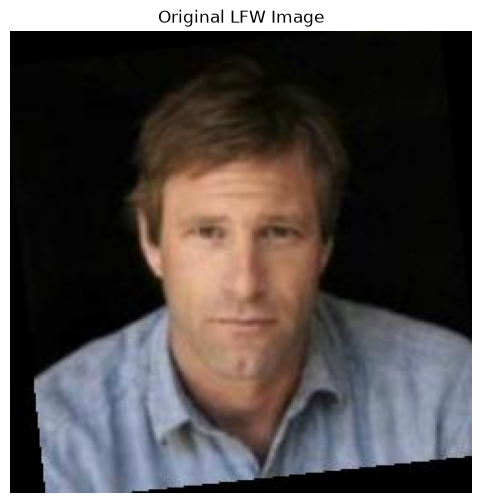

In [ ]:
image = cv2.imread(str(sample_image_path))

if image is None:
    raise ValueError("Unable to load the selected image.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(image_rgb)
plt.title("Original LFW Image")
plt.axis("off")
plt.show()

Perform Face Detection 

In [ ]:
# Convert image into MediaPipe format
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)

# Run face detection
detection_result = landmarker.detect(mp_image)

# Check detected faces
face_count = len(detection_result.face_landmarks)

print("Number of faces detected:", face_count)

Number of faces detected: 1


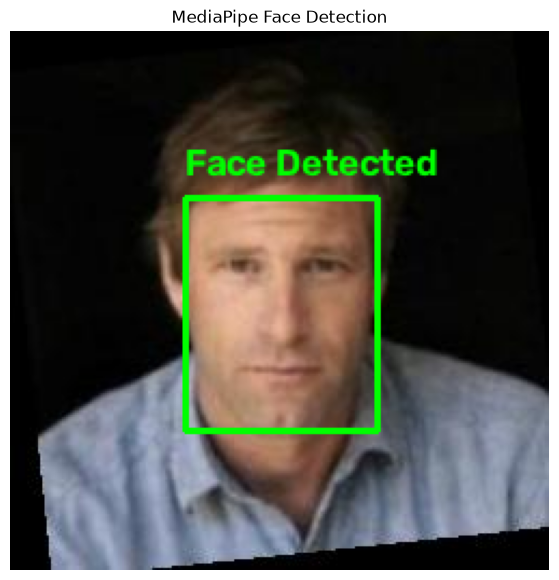

In [ ]:
output_image = image_rgb.copy()

height, width, _ = output_image.shape

for face_landmarks in detection_result.face_landmarks:

    # Extract normalized landmark coordinates
    x_coordinates = [lm.x for lm in face_landmarks]
    y_coordinates = [lm.y for lm in face_landmarks]

    # Calculate bounding box
    x_min = int(min(x_coordinates) * width)
    y_min = int(min(y_coordinates) * height)

    x_max = int(max(x_coordinates) * width)
    y_max = int(max(y_coordinates) * height)

    # Keep coordinates within image boundaries
    x_min = max(0, x_min)
    y_min = max(0, y_min)
    x_max = min(width - 1, x_max)
    y_max = min(height - 1, y_max)

    # Draw bounding box
    cv2.rectangle(
        output_image,
        (x_min, y_min),
        (x_max, y_max),
        (0, 255, 0),
        2
    )

    # Add detection label
    cv2.putText(
        output_image,
        "Face Detected",
        (x_min, max(y_min - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 0),
        2
    )

# Display result
plt.figure(figsize=(7, 7))
plt.imshow(output_image)
plt.title("MediaPipe Face Detection")
plt.axis("off")
plt.show()

In [ ]:
print("========== FACE DETECTION SUMMARY ==========")

print("Image:", sample_image_path.name)
print("Image dimensions:", image.shape[:2])
print("Faces detected:", face_count)

if face_count > 0:
    print("Landmarks per face:",
          len(detection_result.face_landmarks[0]))

print("============================================")

========== FACE DETECTION SUMMARY ==========
Image: Aaron_Eckhart_0001.jpg
Image dimensions: (250, 250)
Faces detected: 1
Landmarks per face: 478


## Facial Landmark Visualization

Objective:
Visualize the 478 facial landmarks extracted by
MediaPipe Face Landmarker.

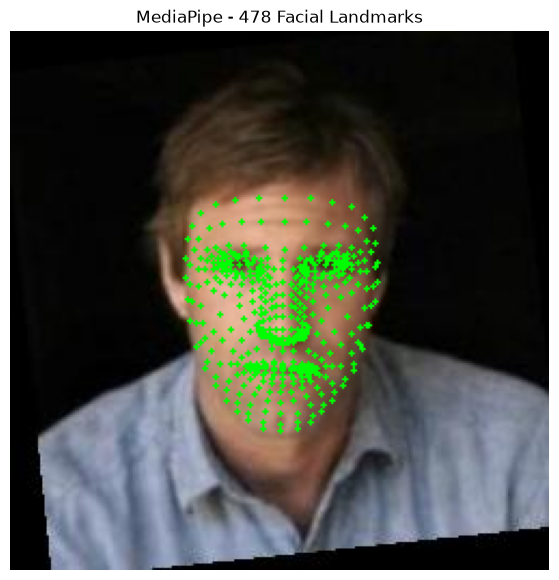

Total landmarks visualized: 478


In [ ]:
# Copy original image
landmark_image = image_rgb.copy()

height, width, _ = landmark_image.shape

# Extract landmarks for the first detected face
face_landmarks = detection_result.face_landmarks[0]

# Draw all 478 landmarks
for landmark in face_landmarks:

    x = int(landmark.x * width)
    y = int(landmark.y * height)

    cv2.circle(
        landmark_image,
        (x, y),
        1,
        (0, 255, 0),
        -1
    )

# Display landmark visualization
plt.figure(figsize=(7, 7))
plt.imshow(landmark_image)
plt.title("MediaPipe - 478 Facial Landmarks")
plt.axis("off")
plt.show()

print("Total landmarks visualized:", len(face_landmarks))

## Multiple-Face Detection

Objective:
Test whether MediaPipe can detect multiple faces
in the same image.

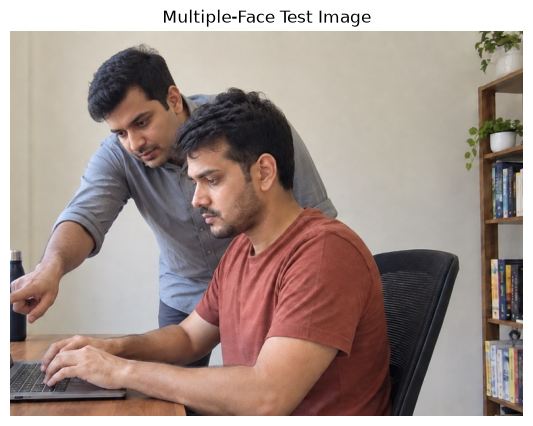

In [ ]:
from pathlib import Path
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt

TEST_IMAGE_PATH = PROJECT_ROOT / "dataset" / "test_images" / "two_faces.jpg"

test_image = cv2.imread(str(TEST_IMAGE_PATH))

if test_image is None:
    raise FileNotFoundError(
        f"Could not load image: {TEST_IMAGE_PATH}"
    )

test_image_rgb = cv2.cvtColor(
    test_image, cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(7, 5))
plt.imshow(test_image_rgb)
plt.title("Multiple-Face Test Image")
plt.axis("off")
plt.show()

In [ ]:
# Convert image to MediaPipe format
mp_test_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=test_image_rgb
)

# Perform face detection
multi_result = landmarker.detect(mp_test_image)

# Count detected faces
multi_face_count = len(multi_result.face_landmarks)

print("Number of faces detected:", multi_face_count)

Number of faces detected: 2


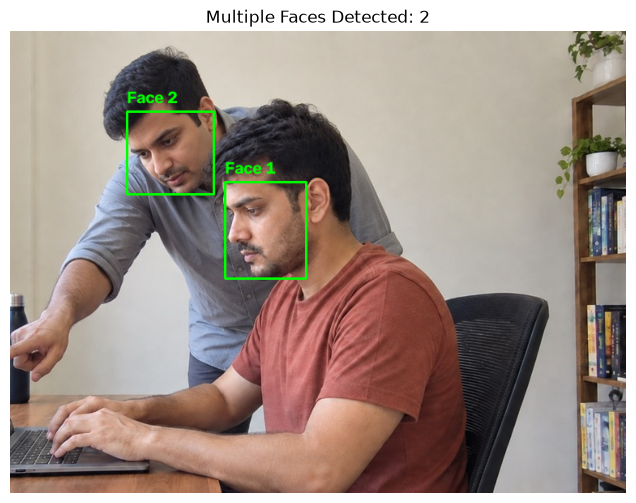

In [ ]:
multi_output = test_image_rgb.copy()

height, width, _ = multi_output.shape

for index, face_landmarks in enumerate(
    multi_result.face_landmarks
):

    x_coords = [lm.x for lm in face_landmarks]
    y_coords = [lm.y for lm in face_landmarks]

    x_min = max(0, int(min(x_coords) * width))
    y_min = max(0, int(min(y_coords) * height))

    x_max = min(width - 1, int(max(x_coords) * width))
    y_max = min(height - 1, int(max(y_coords) * height))

    # Draw bounding box
    cv2.rectangle(
        multi_output,
        (x_min, y_min),
        (x_max, y_max),
        (0, 255, 0),
        2
    )

    # Label each face
    cv2.putText(
        multi_output,
        f"Face {index + 1}",
        (x_min, max(y_min - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (0, 255, 0),
        2
    )

plt.figure(figsize=(9, 6))
plt.imshow(multi_output)
plt.title(f"Multiple Faces Detected: {multi_face_count}")
plt.axis("off")
plt.show()

In [ ]:
print("========== MULTIPLE FACE DETECTION ==========")

print("Total faces detected:", multi_face_count)

if multi_face_count == 0:
    print("Status: No face detected")

elif multi_face_count == 1:
    print("Status: Single face detected")

else:
    print("Status: Multiple faces detected")
    print("Exam monitoring: Multiple-person alert")

print("=============================================")

========== MULTIPLE FACE DETECTION ==========
Total faces detected: 2
Status: Multiple faces detected
Exam monitoring: Multiple-person alert


## No-Face Detection

Objective:
Test MediaPipe Face Landmarker using an image
that does not contain any human face.

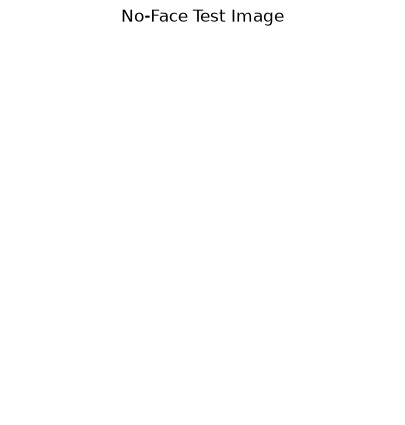

In [ ]:
# Create a blank white image
blank_image = np.ones(
    (250, 250, 3),
    dtype=np.uint8
) * 255

# Display the image
plt.figure(figsize=(5, 5))
plt.imshow(blank_image)
plt.title("No-Face Test Image")
plt.axis("off")
plt.show()

In [ ]:
# Convert image to MediaPipe format
mp_blank_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=blank_image
)

# Perform face detection
no_face_result = landmarker.detect(mp_blank_image)

# Count detected faces
no_face_count = len(no_face_result.face_landmarks)

print("Number of faces detected:", no_face_count)

Number of faces detected: 0


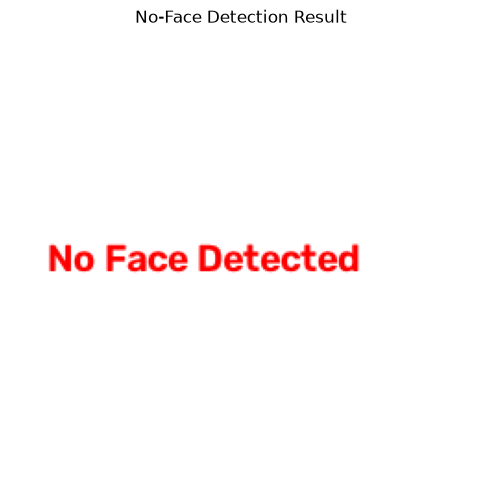

Monitoring Status: NO_FACE_DETECTED


In [ ]:
# HANDLING NO FACE DETECTED CASE
# Create output image
no_face_output = blank_image.copy()

if no_face_count == 0:

    status = "NO_FACE_DETECTED"

    cv2.putText(
        no_face_output,
        "No Face Detected",
        (20, 130),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 0, 0),
        2
    )

else:

    status = "FACE_DETECTED"

    height, width, _ = no_face_output.shape

    for face_landmarks in no_face_result.face_landmarks:

        x_coords = [lm.x for lm in face_landmarks]
        y_coords = [lm.y for lm in face_landmarks]

        x_min = int(min(x_coords) * width)
        y_min = int(min(y_coords) * height)

        x_max = int(max(x_coords) * width)
        y_max = int(max(y_coords) * height)

        cv2.rectangle(
            no_face_output,
            (x_min, y_min),
            (x_max, y_max),
            (0, 255, 0),
            2
        )

# Display output
plt.figure(figsize=(6, 6))
plt.imshow(no_face_output)
plt.title("No-Face Detection Result")
plt.axis("off")
plt.show()

print("Monitoring Status:", status)

In [ ]:
print("========== NO-FACE DETECTION ==========")

print("Faces detected:", no_face_count)

if no_face_count == 0:
    print("Status: No face detected")
    print("Monitoring Event: NO_FACE_DETECTED")
else:
    print("Status: Face detected")

print("=======================================")

========== NO-FACE DETECTION ==========
Faces detected: 0
Status: No face detected
Monitoring Event: NO_FACE_DETECTED


## Real-Time Webcam Face Detection

Objective:
Capture live webcam frames using OpenCV,
detect faces using MediaPipe Face Landmarker,
and display bounding boxes and monitoring status.

In [ ]:
# Initialize webcam
cap = cv2.VideoCapture(0)

# Check whether webcam opened successfully
if not cap.isOpened():
    raise RuntimeError(
        "Could not access webcam. Check camera permissions."
    )

# Set webcam resolution
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

print("Webcam initialized successfully!")
print("Press Q in the webcam window to stop.")

Webcam initialized successfully!
Press Q in the webcam window to stop.


In [ ]:
# Start webcam monitoring
try:

    while cap.isOpened():

        # Capture a frame
        success, frame = cap.read()

        if not success:
            print("Unable to capture webcam frame.")
            break

        # Mirror the webcam frame
        frame = cv2.flip(frame, 1)

        # Convert BGR to RGB
        frame_rgb = cv2.cvtColor(
            frame, cv2.COLOR_BGR2RGB
        )

        # Convert to MediaPipe image format
        mp_frame = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=frame_rgb
        )

        # Run MediaPipe detection
        result = landmarker.detect(mp_frame)

        # Count detected faces
        face_count = len(result.face_landmarks)

        height, width, _ = frame.shape

        # Draw bounding boxes for detected faces
        for index, face_landmarks in enumerate(
            result.face_landmarks
        ):

            x_coords = [lm.x for lm in face_landmarks]
            y_coords = [lm.y for lm in face_landmarks]

            x_min = max(0, int(min(x_coords) * width))
            y_min = max(0, int(min(y_coords) * height))

            x_max = min(width - 1, int(max(x_coords) * width))
            y_max = min(height - 1, int(max(y_coords) * height))

            cv2.rectangle(
                frame,
                (x_min, y_min),
                (x_max, y_max),
                (0, 255, 0),
                2
            )

            cv2.putText(
                frame,
                f"Face {index + 1}",
                (x_min, max(y_min - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 0),
                2
            )

        # Determine monitoring status
        if face_count == 0:
            status = "NO FACE DETECTED"
            color = (0, 0, 255)

        elif face_count == 1:
            status = "SINGLE FACE"
            color = (0, 255, 0)

        else:
            status = "MULTIPLE FACES"
            color = (0, 165, 255)

        # Display face count and status
        cv2.putText(
            frame,
            f"Faces: {face_count}",
            (20, 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            color,
            2
        )

        cv2.putText(
            frame,
            f"Status: {status}",
            (20, 70),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            color,
            2
        )

        # Display webcam output
        cv2.imshow(
            "Exam Engine - Face Monitoring",
            frame
        )

        # Stop when Q or ESC is pressed
        key = cv2.waitKey(1) & 0xFF

        if key == ord('q') or key == 27:
            break

finally:

    # Release webcam and close windows
    cap.release()
    cv2.destroyAllWindows()

    print("Webcam released successfully.")

Webcam released successfully.


## MULTI FACE DETECTION TESTING

Image dimensions: (600, 400, 3)
Faces detected: 4


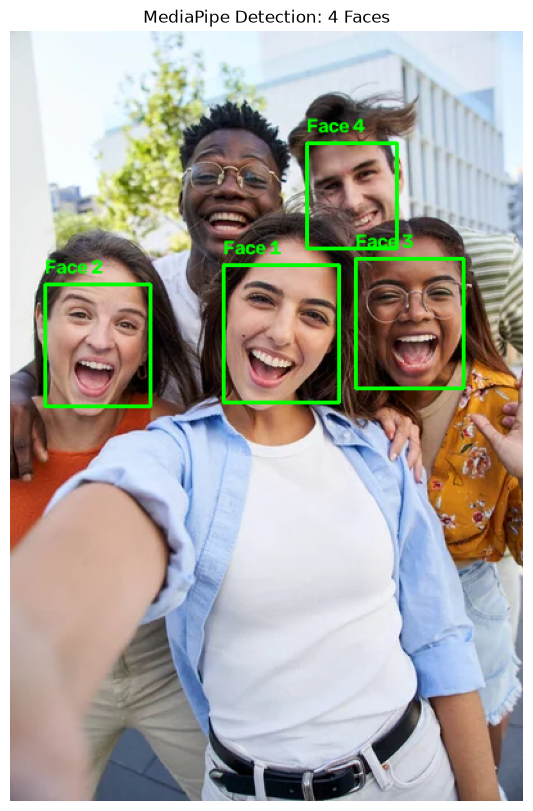

In [ ]:
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt

group_image_path = (
    PROJECT_ROOT / "dataset" / "test_images" / "group_test.jpg"
)

image = cv2.imread(str(group_image_path))

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)

result = landmarker.detect(mp_image)

print("Image dimensions:", image.shape)
print("Faces detected:", len(result.face_landmarks))

# Draw all detected face bounding boxes
height, width, _ = image.shape
output_image = image.copy()

for i, landmarks in enumerate(result.face_landmarks):

    x_coords = [int(p.x * width) for p in landmarks]
    y_coords = [int(p.y * height) for p in landmarks]

    x_min = max(0, min(x_coords))
    y_min = max(0, min(y_coords))
    x_max = min(width - 1, max(x_coords))
    y_max = min(height - 1, max(y_coords))

    cv2.rectangle(
        output_image,
        (x_min, y_min),
        (x_max, y_max),
        (0, 255, 0),
        2
    )

    cv2.putText(
        output_image,
        f"Face {i+1}",
        (x_min, max(20, y_min - 8)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 255, 0),
        2
    )

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB))
plt.title(f"MediaPipe Detection: {len(result.face_landmarks)} Faces")
plt.axis("off")
plt.show()


Faces detected in cropped region: 1


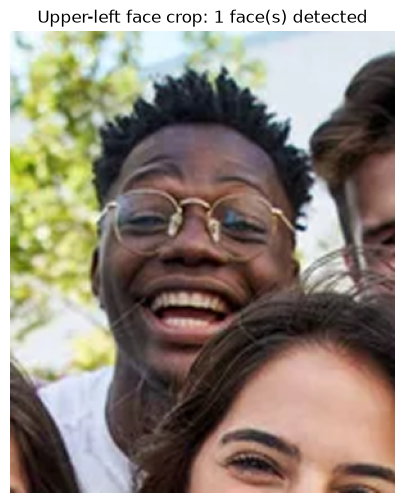

In [35]:

# Load original image
image = cv2.imread(str(group_image_path))

# Crop the upper-left face region
# Original image dimensions: 400 x 600
face_crop = image[40:220, 100:250]

# Enlarge crop 2x
enlarged_crop = cv2.resize(
    face_crop,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_CUBIC
)

# Convert to MediaPipe format
crop_rgb = cv2.cvtColor(
    enlarged_crop,
    cv2.COLOR_BGR2RGB
)

crop_mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=crop_rgb
)

# Detect faces
crop_result = landmarker.detect(crop_mp_image)

print("Faces detected in cropped region:",
      len(crop_result.face_landmarks))

# Display crop
plt.figure(figsize=(6, 6))
plt.imshow(crop_rgb)
plt.title(
    f"Upper-left face crop: "
    f"{len(crop_result.face_landmarks)} face(s) detected"
)
plt.axis("off")
plt.show()


In [36]:
image = cv2.imread(str(group_image_path))

# Upscale entire image 2x
upscaled_image = cv2.resize(
    image,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_CUBIC
)

upscaled_rgb = cv2.cvtColor(
    upscaled_image,
    cv2.COLOR_BGR2RGB
)

upscaled_mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=upscaled_rgb
)

upscaled_result = landmarker.detect(upscaled_mp_image)

print("Original image size:", image.shape)
print("Upscaled image size:", upscaled_image.shape)
print("Faces detected after upscaling:",
      len(upscaled_result.face_landmarks))


Original image size: (600, 400, 3)
Upscaled image size: (1200, 800, 3)
Faces detected after upscaling: 4


In [37]:
def detect_faces_multiscale(image, scale=2.0):

    height, width = image.shape[:2]

    # Overlapping image regions (x1, y1, x2, y2)
    crops = [
        (0, 0, width, height),
        (0, 0, width // 2 + 50, height),
        (width // 2 - 50, 0, width, height),
        (0, 0, width, height // 2 + 50),
        (0, height // 2 - 50, width, height)
    ]

    detections = []

    for x1, y1, x2, y2 in crops:

        crop = image[y1:y2, x1:x2]

        enlarged = cv2.resize(
            crop,
            None,
            fx=scale,
            fy=scale,
            interpolation=cv2.INTER_CUBIC
        )

        rgb = cv2.cvtColor(enlarged, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb
        )

        result = landmarker.detect(mp_image)

        for landmarks in result.face_landmarks:

            xs = [p.x for p in landmarks]
            ys = [p.y for p in landmarks]

            # Map coordinates to original image
            bx1 = x1 + int(min(xs) * enlarged.shape[1] / scale)
            by1 = y1 + int(min(ys) * enlarged.shape[0] / scale)
            bx2 = x1 + int(max(xs) * enlarged.shape[1] / scale)
            by2 = y1 + int(max(ys) * enlarged.shape[0] / scale)

            detections.append([bx1, by1, bx2, by2])

    return detections


# Load image
image = cv2.imread(str(group_image_path))

detections = detect_faces_multiscale(image)

print("Total detections before duplicate removal:", len(detections))


Total detections before duplicate removal: 14


In [38]:
def apply_nms(detections, iou_threshold=0.35):

    if not detections:
        return []

    boxes = []
    scores = []

    for x1, y1, x2, y2 in detections:

        boxes.append([
            int(x1),
            int(y1),
            int(x2 - x1),
            int(y2 - y1)
        ])

        # Equal scores because MediaPipe landmarks
        # do not provide a detection confidence here.
        scores.append(1.0)

    indices = cv2.dnn.NMSBoxes(
        boxes,
        scores,
        score_threshold=0.0,
        nms_threshold=iou_threshold
    )

    if len(indices) == 0:
        return []

    indices = np.array(indices).flatten()

    return [detections[i] for i in indices]


# Remove duplicate detections
final_detections = apply_nms(
    detections,
    iou_threshold=0.35
)

print("Raw detections:", len(detections))
print("Detections after NMS:", len(final_detections))


Raw detections: 14
Detections after NMS: 5


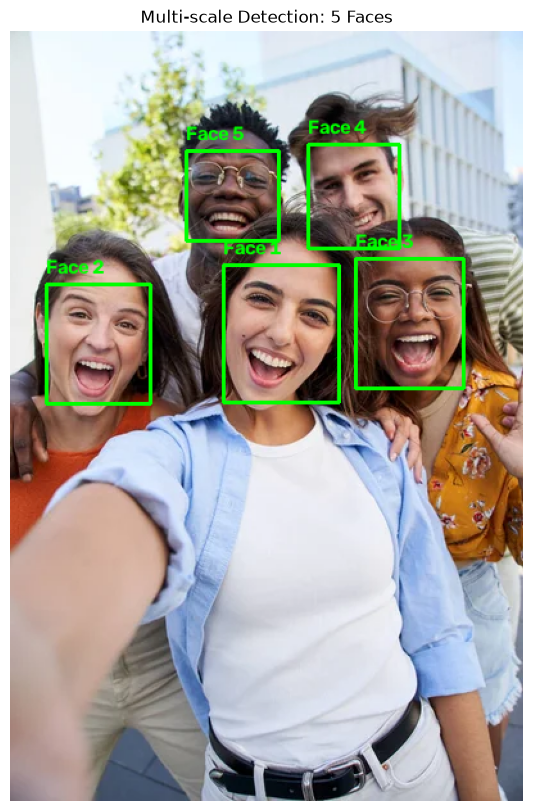

In [39]:
output_image = image.copy()

for i, (x1, y1, x2, y2) in enumerate(final_detections):

    cv2.rectangle(
        output_image,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    cv2.putText(
        output_image,
        f"Face {i+1}",
        (x1, max(20, y1 - 8)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 255, 0),
        2
    )

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB))
plt.title(f"Multi-scale Detection: {len(final_detections)} Faces")
plt.axis("off")
plt.show()


In [44]:
# Load second group image
group_image_2_path = (
    PROJECT_ROOT / "dataset" / "test_images" / "group_test_2.jpg"
)

image_2 = cv2.imread(str(group_image_2_path))

if image_2 is None:
    raise FileNotFoundError(f"Image not found: {group_image_2_path}")

print("Image dimensions:", image_2.shape)

Image dimensions: (360, 540, 3)


In [45]:
detections_2 = detect_faces_multiscale(image_2)

final_detections_2 = apply_nms(
    detections_2,
    iou_threshold=0.35
)

print("Raw detections:", len(detections_2))
print("Final detected faces:", len(final_detections_2))

Raw detections: 24
Final detected faces: 9


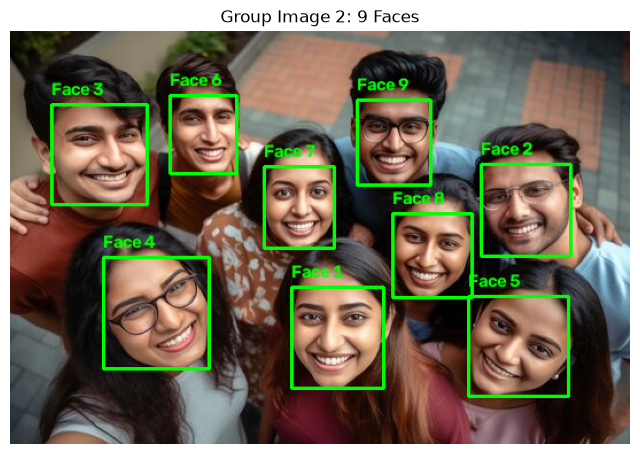

In [46]:
output_image_2 = image_2.copy()

for i, (x1, y1, x2, y2) in enumerate(final_detections_2):

    cv2.rectangle(
        output_image_2,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    cv2.putText(
        output_image_2,
        f"Face {i+1}",
        (x1, max(20, y1 - 8)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 255, 0),
        2
    )

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(output_image_2, cv2.COLOR_BGR2RGB))
plt.title(f"Group Image 2: {len(final_detections_2)} Faces")
plt.axis("off")
plt.show()